# Challenge 1 

Partie A — Méthode Traditionnelle
À partir du fichier 
Raisin_Dataset.csv :
1. Séparer les variables 
X et la cible 
y , puis
diviser les données en ensemble train/test.
2. Normaliser les données avec 
normalisées.
MinMaxScaler
: ajuster sur le train, puis transformer le train
et le test.
3. Entraîner un modèle 
SVC sur les données
4. Effectuer les prédictions et calculer
l'Accuracy et le MCC

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import MinMaxScaler 
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, matthews_corrcoef


df = pd.read_csv("Raisin_Dataset.csv") #read data 
df.head()  #affiche 5 ligne from data 

y = df['Class'] #target variable
x = df.drop('Class',axis=1) #feature variables

X_train, X_test,y_train,y_test= train_test_split(
    x,
    y,
    random_state=42,
    test_size=0.2
)
#Normalisation 
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Entrainement de Model 
model = SVC()
model.fit(X_train_scaled, y_train)

#predict/eveluate
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

print("Accuracy:", accuracy)
print("MCC:", mcc)


Accuracy: 0.8777777777777778
MCC: 0.7550717466600693


Partie B — Utilisation de Pipeline
Automatisation du flux de travail :
1. Construire un 
Pipeline enchaînant le
MinMaxScaler et le classifieur 
SVC .
2. Entraîner le pipeline directement sur les
données d'entraînement brutes.
3. Effectuer une prédiction sur les données de
test brutes.
4. Calculer l'Accuracy et le MCC

In [2]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("svc", SVC())
])

pipeline.fit(X_train, y_train)
y_pred_pipeline = pipeline.predict(X_test)


accuracy_pipeline = accuracy_score(y_test, y_pred_pipeline)
mcc_pipeline = matthews_corrcoef(y_test, y_pred_pipeline)

print("Accuracy:", accuracy_pipeline)
print("MCC:", mcc_pipeline)


Accuracy: 0.8777777777777778
MCC: 0.7550717466600693


Questions de Comparaison & Analyse
- Question 1
Quelle est la différence fondamentale entre les
deux méthodes ?
- Question 2
Pourquoi ne faut-il jamais ajuster (fit) le scaler
sur les données de test ?
- Question 3
Quels avantages clés apporte l'utilisation d'un
Pipeline dans un projet ML ?
- Question 4
Les deux méthodes devraient-elles donner des
résultats identiques ? Pourquoi ?

# Challenge2

Consignes — Travail à Réaliser
1. Construire trois pipelines distincts :
SVM avec prétraitement 
MinMaxScaler
KNN avec prétraitement 
MinMaxScaler
Decision Tree sans normalisation (données brutes)
2. Entraîner chaque pipeline sur les mêmes données d'entraînement.
3. Effectuer les prédictions sur le jeu de test pour chaque modèle.
4. Calculer l'accuracy et afficher la matrice de confusion pour chacun des trois modèles.
5. Comparer les résultats et identifier l'algorithme le plus performant sur ce jeu de données

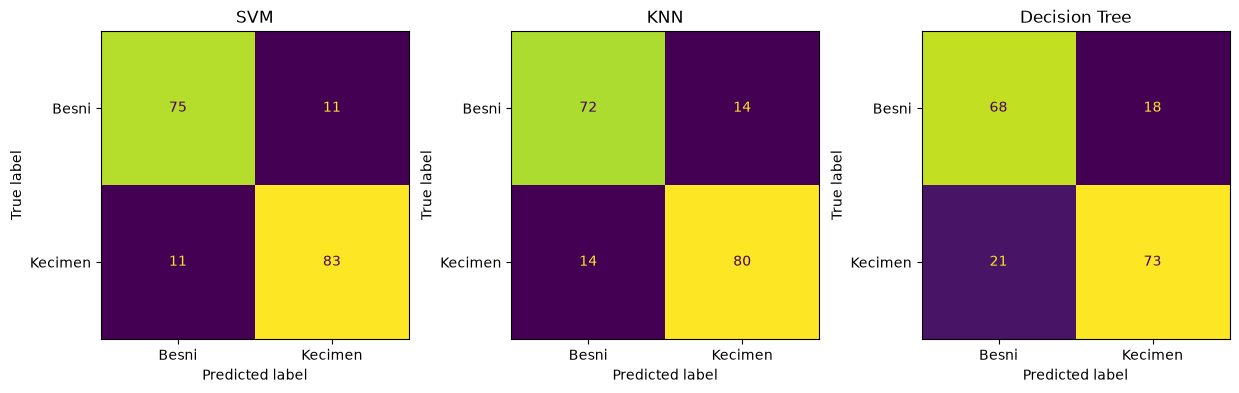

SVM: 0.8778
KNN: 0.8444
Decision Tree: 0.7833
 BEST MODEL : SVM


In [11]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Définition des modèles
pipelines = {
    "SVM": Pipeline([("scaler", MinMaxScaler()), ("model", SVC())]),
    "KNN": Pipeline([("scaler", MinMaxScaler()), ("model", KNeighborsClassifier())]),
    "Decision Tree": Pipeline([("model", DecisionTreeClassifier())])
}

results = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, pipelines.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results[name] = accuracy_score(y_test, y_pred)

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, ax=ax, colorbar=False
    )
    ax.set_title(name)
    
plt.show()

# Comparaison
for name, score in results.items():
    print(f"{name}: {score:.4f}")

print(" BEST MODEL :", max(results, key=results.get))


Questions de Réflexion & Analyse
- Question 1
Pourquoi utiliser plusieurs pipelines indépendants ?
- Question 2
Évaluation
Accuracy & Confusion
Pourquoi normaliser pour SVM et KNN, mais pas
nécessairement pour Decision Tree ?
- Question 3
Comment interpréter une matrice de confusion ?
- Question 4
Le modèle ayant la meilleure accuracy est-il toujours
le meilleur choix ?
- Question 5
Quelle différence existe entre évaluer un modèle sur un seul jeu de test et utiliser la cross-validation (validation
croisée) ?

# Challenge 3

Consignes — Travail à Réaliser
1. Créer un DataFrame : Inclure des variables numériques (
( Vi
lle ) et une cible binaire (
LogisticRegression
Classifieur
Age , 
Prédictions y
Accuracy
Salaire ), une variable catégorielle
A_achete ).
2. Séparer les données : Isoler les variables explicatives 
X et la cible 
y .
3. Split Train/Test : Diviser le dataset en ensembles d'entraînement et de test.
4. Identifier les colonnes : Lister les noms des colonnes numériques et catégorielles.
5. Construire le ColumnTransformer :
Standardiser les variables numériques avec 
StandardScaler
Encoder les variables catégorielles avec 
OneHotEncoder
6. Assembler le Pipeline : Intégrer le 
ColumnTransformer et un modèle 
même chaîne.
LogisticRegression dans une
7. Entraîner & Évaluer : Entraîner la pipeline sur le train set, effectuer les prédictions sur le test set et calculer
l'Accuracy

In [12]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Création du DataFrame
df = pd.DataFrame({
    "Age": [22, 25, 30, 35, 40, 28, 45, 32, 26, 38],
    "Salaire": [3000, 4000, 5000, 6000, 7000, 3500, 8000, 5500, 3200, 6500],
    "Ville": ["Casa", "Rabat", "Casa", "Fes", "Rabat", "Fes", "Casa", "Rabat", "Fes", "Casa"],
    "A_achete": [0, 0, 1, 1, 1, 0, 1, 1, 0, 1]
})


X = df.drop("A_achete", axis=1)
y = df["A_achete"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

num_cols = ["Age", "Salaire"]
cat_cols = ["Ville"]


preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])


pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression())
])


pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print(y_pred)
print("Accuracy :", accuracy_score(y_test, y_pred))


[0 1]
Accuracy : 1.0


Questions de Réflexion & Analyse
- Question 1
Quelle est la différence essentielle entre Pipeline et
ColumnTransformer ?
- Question 2
Pourquoi appliquer des traitements différents aux
variables numériques et catégorielles ?
- Question 3
Quel est l'intérêt d'intégrer le prétraitement et le
modèle dans un même Pipeline ?
- Question 4
Pourquoi le prétraitement doit-il être ajusté (fit)
uniquement sur les données d'entraînement ?
- Question 5
Pourquoi une accuracy calculée sur un très petit jeu de test peut-elle être peu fiable ou trompeuse ?

# Challenge 4

Consignes — Travail à Réaliser
1. Chargement & Split : Charger 
Val (Fold 5)
Raisin_Dataset.csv , séparer 
Jeu de Test Sanctuarisé
X_test / y_test
Évaluation Finale Réservée
X et y , puis diviser en ensembles Train et Test.
2. Définir 3 Pipelines : SVM (+ MinMaxScaler), KNN (+ MinMaxScaler) et Decision Tree (brut).
3. Validation Croisée : Appliquer 
scoring="accuracy" .
cross_val_score() sur les données d'entraînement avec 
cv=5 et
4. Analyser la Stabilité : Pour chaque modèle, afficher les 5 scores, la moyenne (μ), l'écart-type (σ), le min et le max.
5. Sélection du Modèle : Comparer les modèles et retenir le meilleur candidat (équilibre entre performance moyenne
et faible variabilité).
6. Évaluation Finale : Ré-entraîner le modèle retenu sur 
l'intégralité du jeu d'entraînement et évaluer son accuracy
finale sur le 
jeu de test

In [16]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


df = pd.read_csv("Raisin_Dataset.csv")

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

pipelines = {
    "SVM": Pipeline([("scaler", MinMaxScaler()), ("model", SVC())]),
    "KNN": Pipeline([("scaler", MinMaxScaler()), ("model", KNeighborsClassifier())]),
    "Decision Tree": Pipeline([("model", DecisionTreeClassifier(random_state=42))])
}

# 3. Validation croisée et analyse de stabilité
results = {}

for name, model in pipelines.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
        )

    results[name] = (scores.mean(), scores.std())

    print(f"\n{name}")
    print("Scores :", scores)
    print("Moyenne :", scores.mean())
    print("Écart-type :", scores.std())
    print("Min :", scores.min())
    print("Max :", scores.max())


best_model = max(results, key=lambda x: results[x][0] - results[x][1])
print("Best  Model :", best_model)


final_model = pipelines[best_model]
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

print("Accuracy finale :", accuracy_score(y_test, y_pred))



SVM
Scores : [0.77777778 0.90277778 0.85416667 0.86111111 0.93055556]
Moyenne : 0.8652777777777778
Écart-type : 0.05189317136741502
Min : 0.7777777777777778
Max : 0.9305555555555556

KNN
Scores : [0.8125     0.89583333 0.83333333 0.83333333 0.89583333]
Moyenne : 0.8541666666666667
Écart-type : 0.034860834438919824
Min : 0.8125
Max : 0.8958333333333334

Decision Tree
Scores : [0.77777778 0.88194444 0.73611111 0.83333333 0.84027778]
Moyenne : 0.8138888888888889
Écart-type : 0.051106581924928035
Min : 0.7361111111111112
Max : 0.8819444444444444
Best  Model : KNN
Accuracy finale : 0.8666666666666667


Questions de Réflexion & Compréhension
- Question 1
Quel est le principe de la cross-validation à 5 folds ?
- Question 2
Pourquoi effectuer la CV sur le Train set et garder le
Test set à part ?
- Question 3
Quel est le rôle de la moyenne et de l'écart-type des
scores de CV ?
- Question 4
Pourquoi intégrer le prétraitement dans la Pipeline lors
de la CV ?
- Question 5
Comment la CV aide-t-elle à comparer objectivement
plusieurs modèles ?
- Question 6
Pourquoi conserver un jeu de test indépendant pour
l'évaluation finale ?

# Challenge 5

Consignes — Travail à Réaliser
1. Préparation des Données : Charger 
avec 
train_test_split() .
Raisin_Dataset.csv et diviser en ensembles d'entraînement et de test
2. Comparaison Initiale : Construire les pipelines (
SVM , 
KNN , 
initiales avec 
cross_val_score(cv=5) .
Decision Tree ) et évaluer leurs performances
3. Optimisation des Hyperparamètres : Configurer et exécuter 
GridSearchCV sur le modèle retenu afin de
déterminer la meilleure combinaison de paramètres.
4. Évaluation du Modèle Optimisé : Tester le meilleur pipeline (
best_estimator_ ) sur le jeu de test
indépendant.
5. Sauvegarde & Rechargement : Sauvegarder le pipeline complet à l'aide de 
joblib.dump() , puis recharger le
fichier pour effectuer une prédiction de vérification

In [17]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


df = pd.read_csv("Raisin_Dataset.csv")
X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


pipelines = {
    "SVM": Pipeline([("scaler", MinMaxScaler()), ("model", SVC())]),
    "KNN": Pipeline([("scaler", MinMaxScaler()), ("model", KNeighborsClassifier())]),
    "Tree": Pipeline([("model", DecisionTreeClassifier(random_state=42))])
}

scores = {name: cross_val_score(
    model,
    X_train,
    y_train,
    cv=5
    ).mean()
        for name, model in pipelines.items()}

print(scores)


best_name = max(scores, key=scores.get)

params = {
    "SVM": {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9]},
    "Tree": {"model__max_depth": [None, 3, 5, 10]}
}

grid = GridSearchCV(pipelines[best_name], params[best_name], cv=5)
grid.fit(X_train, y_train)


best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("Best param:", grid.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))


joblib.dump(best_model, "model.pkl")
loaded_model = joblib.load("model.pkl")



{'SVM': np.float64(0.8652777777777778), 'KNN': np.float64(0.8541666666666667), 'Tree': np.float64(0.8138888888888889)}
Best param: {'model__C': 1, 'model__kernel': 'rbf'}
Accuracy: 0.8833333333333333
